# Descriptor selection for phonon inverse design

Which phonon descriptors are worth building an inverse-design model around, and which structural/compositional
descriptors predict them? Every candidate target goes through four checks:

1. **Noise floor**: is the MLIP's uncertainty on it small compared to its spread across the dataset?
2. **Redundancy**: does it carry information the other targets don't?
3. **Learnability**: can it be predicted from composition alone, or only with relaxed geometry or instability
   information? Evaluated with CV grouped by formula, plus a held-out anion family.
4. **Invertibility**: does fixing it pin down the chemistry, or do many chemistries reach the same value?

**Inputs** (build them first):

```bash
# selected polymorphs -> data/mlip_stable_polymorphs/design_descriptors{.csv,_quantiles.npz}
uv run python3 scripts/analysis/extract_design_descriptors.py --root mnt/mlip_phonons_mp/MACE-matpes-r2scan-omat-ft --workers 16
# noise floor: same descriptors from every benchmark model
uv run python3 scripts/analysis/extract_design_descriptors.py --mlip-root data/mlip_phonons \
    --out-csv data/phonon_benchmark/design_descriptors_models.csv
uv run python3 scripts/analysis/extract_design_descriptors.py --mlip-root out/gauntlet/mlip --pattern "*/CsPbBr3/soft_mode" \
    --out-csv data/phonon_benchmark/design_descriptors_gauntlet.csv
```

The notebook also uses `polymorph_clusters.csv` (cluster_polymorphs.py: vDOS gap and stability flag),
`data/mp_perovskites/composition_features.csv` (extract_composition_features.py: site radii, masses, electronegativity,
oxidation states, tolerance/octahedral factors)
`data/phonon_benchmark/metrics.csv` (compare_phonons.py), and for the halide-interpolation section the mixed-halide
sweep's `data/mixed_halides/analysis/` (design_descriptors, selection/, and composition_features from
extract_composition_features.py --compositions). See `src/analysis/design_descriptors.py` for definitions.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import leaves_list, linkage
from scipy.spatial.distance import squareform
from sklearn.decomposition import PCA
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score
from sklearn.model_selection import GroupKFold, GroupShuffleSplit
from sklearn.preprocessing import StandardScaler

try:
    plt.style.use("my_style")
except OSError:
    pass

DATA = PROJECT_ROOT / "data" / "mlip_stable_polymorphs"
DESIGN_CSV = DATA / "design_descriptors.csv"
QUANTILES_NPZ = DATA / "design_descriptors_quantiles.npz"
POLYMORPHS_CSV = DATA / "polymorph_clusters.csv"
COMP_CSV = PROJECT_ROOT / "data" / "mp_perovskites" / "composition_features.csv"
BENCH = PROJECT_ROOT / "data" / "phonon_benchmark"
NOISE_CSVS = {"gauntlet (Pnma CsPbBr3, relaxed per model)": BENCH / "design_descriptors_gauntlet.csv",
              "benchmark (5 cubic cells, DFT geometry)": BENCH / "design_descriptors_models.csv"}
DFPT_METRICS_CSV = BENCH / "metrics.csv"
MIXED = PROJECT_ROOT / "data" / "mixed_halides"
MIXED_DESIGN_CSV = MIXED / "analysis" / "design_descriptors.csv"
MIXED_SELECTION_CSV = MIXED / "analysis" / "selection" / "stable_polymorphs.csv"
MIXED_COMP_CSV = MIXED / "analysis" / "composition_features.csv"
MIXED_SERIES_CSV = MIXED / "compositions.csv"  # framework, halide pair and MP end members of each composition
OUT_DIR = DATA

HIGHLIGHT, CONTEXT = "#2a78d6", "#c8c7c2"  # cluster_polymorphs.py's colours
PCT = r"\%" if plt.rcParams["text.usetex"] else "%"  # my_style renders with LaTeX, where a bare % starts a comment
SEED = 0

## Load and merge

One row per selected polymorph. Rows are dropped if extraction failed, if the polymorph is not dynamically stable
(stable_polymorphs.csv's fallback rows for formulas with no stable state), if a cation couldn't be assigned to A or B, or if the structure is an antiperovskite (no A or B sublattice at all).

In [2]:
design = pd.read_csv(DESIGN_CSV)
poly = pd.read_csv(POLYMORPHS_CSV)
poly["key"] = poly["run_name"] + "/" + poly["state"]  # as extract_design_descriptors.py keys rows
comp = pd.read_csv(COMP_CSV).rename(columns={"name": "run_name"})

poly_cols = ["key", "dynamically_stable", "chem_cluster", "mp_x_site", "crystal_system", "spacegroup_number",
             "vdos_cluster", "vdos_mean_cm1", "vdos_max_cm1", "vdos_gap_width_cm1", "mp_theoretical"]
df = design.merge(poly[poly_cols], on="key", how="inner").merge(comp, on="run_name", how="left")

n0 = len(df)
if "error" in df:
    df = df[df["error"].isna()]
# n_A/n_B = 0: antiperovskites (K3IO, Rb3IO), where the structural check puts a cation on the X site
df = df[df["dynamically_stable"].astype(bool) & (df["sublattice_unassigned"] == 0)
        & (df["n_A"] > 0) & (df["n_B"] > 0)].reset_index(drop=True)
print(f"{len(df)}/{n0} polymorphs kept, {df['formula'].nunique()} formulas")

# anion family for the held-out-anion test: chalcogenides/nitrides are too few to hold out alone
family = {"O": "oxide", "F": "fluoride", "Cl": "chloride", "Br": "bromide/iodide", "I": "bromide/iodide"}
df["anion_family"] = df["mp_x_site"].map(family).fillna("other")
print(df["anion_family"].value_counts().to_string())
# radii/oxidation states are NaN mostly for intermetallics and metal-X antiperovskites, which have no ionic charge balance
print("\ncomposition features missing:", df[["mass_A", "r_A", "tolerance_factor"]].isna().mean().round(3).to_dict())
print("oxidation states from:", df["oxi_source"].str.replace(r"^guess[1-9]\d*$", "guess>0", regex=True).value_counts().to_dict())
print(f"\nMP 'theoretical' entries: {df['mp_theoretical'].astype(bool).mean():.0%}")

2657/2762 polymorphs kept, 2613 formulas
anion_family
oxide             1617
fluoride           320
other              271
chloride           258
bromide/iodide     191

composition features missing: {'mass_A': 0.002, 'r_A': 0.099, 'tolerance_factor': 0.114}
oxidation states from: {'guess0': 2247, 'none': 261, 'bv': 66, 'all_states': 62, 'guess>0': 21}

MP 'theoretical' entries: 68%


## Candidate targets (phonon side)

Grouped by what they measure. Frequency targets are logged, because perovskite frequencies span roughly a factor of 5 from
iodides to oxides, so errors and correlations should be relative. The **stiffness** targets ($k_s$, on-site force constants)
contain no mass, so comparing them with the frequency targets shows how much of a target is mass and how much is bonding.

In [3]:
def phonon_targets(d: pd.DataFrame) -> pd.DataFrame:
    # Targets computable from design_descriptors alone, so they apply to the benchmark tables too.
    t = pd.DataFrame(index=d.index)
    t["log_omega_log"] = np.log(d["omega_log_cm1"])               # overall frequency scale
    t["log_omega_max"] = np.log(d["omega_max_cm1"])
    for s in "ABX":                                                # mass-free bond stiffness per sublattice
        t[f"log_k_{s}"] = np.log(d[f"k_{s}_eV_A2"].where(d[f"k_{s}_eV_A2"] > 0))
    for s in "ABX":                                                # where s sits in the spectrum, scale-free
        t[f"rel_centroid_{s}"] = d[f"omega_mean_{s}_cm1"] / d["omega_mean_cm1"]
        t[f"rel_width_{s}"] = d[f"omega_std_{s}_cm1"] / d["omega_mean_cm1"]
    t["low_enrich_A"] = d["low_enrich_A"]                          # A-site rattling
    t["low_enrich_X"] = d["low_enrich_X"]                          # octahedral tilt/rotation weight
    t["high_enrich_B"] = d["high_enrich_B"]                        # B-X stretching
    for s in "ABX":
        t[f"log_msd_{s}"] = np.log(d[f"msd_{s}_A2"])
    t["cv_300K"] = d["cv_kB_per_atom"]
    t["s_300K"] = d["s_kB_per_atom"]
    return t


T = phonon_targets(df)
T["rel_gap"] = df["vdos_gap_width_cm1"] / df["vdos_max_cm1"]       # largest gap / bandwidth
T["log_distortion_energy"] = np.log1p(df["distortion_energy_meV_per_atom"].clip(lower=0))
T["soft_mode_depth"] = (-df["omega_min_symmetric_cm1"]).clip(lower=0)  # parent-structure instability, cm-1
# built from the same calculations as the I input tier, so they're never scored with it
INSTABILITY_TARGETS = ["log_distortion_energy", "soft_mode_depth"]
print(T.describe().T[["mean", "std", "min", "max"]].round(3).to_string())

                         mean     std    min      max
log_omega_log           5.179   0.443  3.788    5.948
log_omega_max           6.245   0.428  4.749    6.964
log_k_A                 1.419   0.765 -1.023    2.696
log_k_B                 2.587   0.571  0.444    3.527
log_k_X                 1.873   0.499  0.489    2.682
rel_centroid_A          0.472   0.142  0.188    1.625
rel_width_A             0.188   0.055  0.059    0.394
rel_centroid_B          1.008   0.434  0.314    2.779
rel_width_B             0.440   0.143  0.161    1.423
rel_centroid_X          1.173   0.167  0.466    1.437
rel_width_X             0.531   0.123  0.204    0.962
low_enrich_A            2.857   1.151  0.043    7.407
low_enrich_X            0.421   0.365  0.015    1.648
high_enrich_B           1.000   1.438  0.003    5.003
log_msd_A              -4.455   0.759 -5.788   -2.135
log_msd_B              -5.000   0.732 -6.131   -2.181
log_msd_X              -4.332   0.675 -5.694   -1.779
cv_300K                 2.62

### Spectral shape: the vDOS quantile function as scale × shape

The quantile function $Q(p)$ (the frequency below which a fraction $p$ of the modes lie) splits as $Q(p) = \bar\omega\,\tilde Q(p)$.
The scale $\bar\omega$ is already a target above. PCA on $\tilde Q$ gives a few scale-free shape coordinates
(`shape_pc*`), which serve as the functional target. With $\bar\omega$ the mean of $Q$, Euclidean distance on $Q$ is the
Wasserstein-2 distance (up to a factor) and splits exactly into a scale part and a shape part.

fraction of pairwise W2^2 that is pure frequency scale: 63% (median over pairs)
shape PCA explained variance: [0.684 0.109 0.092 0.033 0.025 0.014]


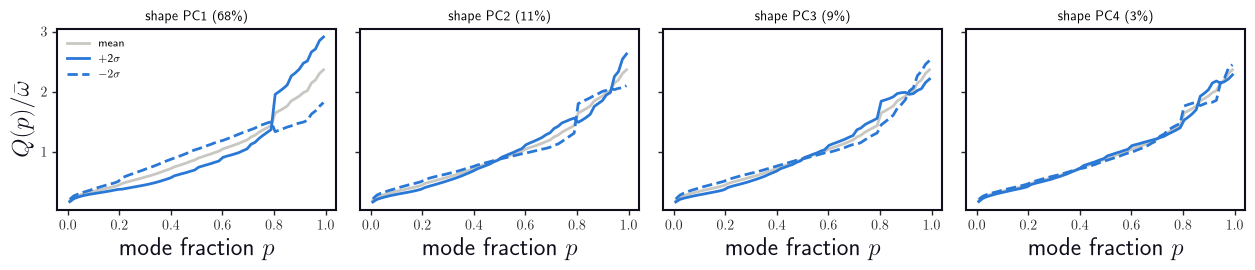

In [4]:
qz = np.load(QUANTILES_NPZ)
qmap = dict(zip(qz["keys"], qz["quantiles_cm1"]))
Q = np.array([qmap[k] for k in df["key"]])
levels = qz["levels"]
scale = Q.mean(axis=1, keepdims=True)
Q_shape = Q / scale

# W2^2 between two spectra = (scale difference)^2 + scale-weighted shape difference; report the split on random pairs
rng = np.random.default_rng(SEED)
i, j = rng.integers(0, len(Q), (2, 5000))
w2_total = ((Q[i] - Q[j]) ** 2).mean(axis=1)
w2_scale = (scale[i, 0] - scale[j, 0]) ** 2
distinct = w2_total > 0  # i == j, or two copies of one spectrum
print(f"fraction of pairwise W2^2 that is pure frequency scale: {np.median(w2_scale[distinct] / w2_total[distinct]):.0%} "
      "(median over pairs)")

shape_pca = PCA(n_components=6, random_state=SEED).fit(Q_shape)
print("shape PCA explained variance:", np.round(shape_pca.explained_variance_ratio_, 3))
n_shape = int(np.searchsorted(np.cumsum(shape_pca.explained_variance_ratio_), 0.9) + 1)
scores = shape_pca.transform(Q_shape)
for k in range(n_shape):
    T[f"shape_pc{k + 1}"] = scores[:, k]

fig, axes = plt.subplots(1, n_shape, figsize=(3.2 * n_shape, 2.8), sharey=True, squeeze=False)
mean_shape = Q_shape.mean(axis=0)
for k, ax in enumerate(axes[0]):
    amp = 2 * np.sqrt(shape_pca.explained_variance_[k])
    ax.plot(levels, mean_shape, color=CONTEXT, lw=2, label="mean")
    ax.plot(levels, mean_shape + amp * shape_pca.components_[k], color=HIGHLIGHT, lw=2, label=r"+2$\sigma$")
    ax.plot(levels, mean_shape - amp * shape_pca.components_[k], color=HIGHLIGHT, lw=2, ls="--", label=r"$-2\sigma$")
    ax.set_title(f"shape PC{k + 1} ({100 * shape_pca.explained_variance_ratio_[k]:.0f}{PCT})", fontsize=10)
    ax.set_xlabel("mode fraction $p$")
axes[0, 0].set_ylabel(r"$Q(p)/\bar\omega$")
axes[0, 0].legend(fontsize=8, frameon=False)
fig.tight_layout()

## Candidate inputs (structure/composition side), in tiers by what's needed to compute them

| tier | needs | contents |
|---|---|---|
| **M** | formula | site masses and reduced masses: the "trivial" part of any frequency target |
| **C** | formula + site assignment | radii, tolerance/octahedral factors, Bartel τ, electronegativity, oxidation states, site heterogeneity |
| **C+G** | + one MLIP relaxation | BX₆ distortion, B–X–B angle (tilt), A-site ECoN and A–X distances, realized tolerance factor, bond-valence deviations, GII |
| **C+G+I** | + phonons of the parent structure | distortion energy and soft-mode frequency of the symmetric/cubic parent |

For inverse design, a target that's learnable from **C** can be screened over any enumerated composition for free. One that needs **G**
needs a relaxation per candidate, which suggests the two-stage model composition → geometry → phonons.

In [5]:
def bartel_tau(r_a, r_b, r_x, n_a):
    # Bartel et al., Sci. Adv. 5, eaav0693 (2019); < 4.18 predicts perovskite. Needs r_A > r_B.
    ratio = r_a / r_b
    tau = r_x / r_b - n_a * (n_a - ratio / np.log(ratio))
    return tau.where(ratio > 1)


M_FEATURES = ["mass_A", "mass_B", "mass_X", "log_mu_BX", "log_mu_AX", "log_mA_over_mX"]
C_FEATURES = M_FEATURES + [
    "r_A", "r_B", "r_X", "tolerance_factor", "octahedral_factor", "en_A", "en_B", "en_X",
    "oxidation_A", "oxidation_B", "oxidation_X", "n_species_A", "n_species_B", "n_species_X",
    "mass_cv_A", "mass_cv_B", "oxi_spread_A", "oxi_spread_B",
    "x_frac_F", "x_frac_Cl", "x_frac_Br", "x_frac_I",  # X-site halide shares: puts mixed halides between their end members
    "tau_bartel"]
G_FEATURES = ["a_pc_A", "oct_d_BX", "oct_d_BX_std_A", "oct_bond_distortion", "oct_quadratic_elongation",
              "oct_angle_variance_deg2", "oct_off_centering_A", "bxb_angle_mean_deg", "bxb_angle_min_deg",
              "tilt_proxy_deg", "A_econ", "d_AX_mean_A", "d_AX_min_A", "d_AX_rel_spread", "t_geom",
              "gii", "bvs_dev_A", "bvs_dev_B", "bvs_dev_X"]
I_FEATURES = ["distortion_energy_meV_per_atom", "omega_min_symmetric_cm1",
              "cubic_distortion_energy_meV_per_atom", "cubic_omega_min_cm1"]


def input_features(d: pd.DataFrame) -> pd.DataFrame:
    # every tier's inputs for a merged descriptor + composition table (the mixed-halide section reuses it)
    x = pd.DataFrame(index=d.index)
    for c in ["mass_A", "mass_B", "mass_X"]:
        x[c] = d[c]
    x["log_mu_BX"] = np.log(d["mass_B"] * d["mass_X"] / (d["mass_B"] + d["mass_X"]))
    x["log_mu_AX"] = np.log(d["mass_A"] * d["mass_X"] / (d["mass_A"] + d["mass_X"]))
    x["log_mA_over_mX"] = np.log(d["mass_A"] / d["mass_X"])
    x["tau_bartel"] = bartel_tau(d["r_A"], d["r_B"], d["r_X"], d["oxidation_A"])
    for c in C_FEATURES + G_FEATURES + I_FEATURES:
        if c not in x:
            x[c] = d[c]
    return x[C_FEATURES + G_FEATURES + I_FEATURES]


X_all = input_features(df)
TIERS = {"M": M_FEATURES, "C": C_FEATURES, "C+G": C_FEATURES + G_FEATURES,
         "C+G+I": C_FEATURES + G_FEATURES + I_FEATURES}
print({k: len(v) for k, v in TIERS.items()})
print("missing fraction (top):")
print(X_all.isna().mean().sort_values(ascending=False).head(6).round(2).to_string())


{'M': 6, 'C': 29, 'C+G': 48, 'C+G+I': 52}
missing fraction (top):
cubic_omega_min_cm1                     0.87
cubic_distortion_energy_meV_per_atom    0.87
bvs_dev_A                               0.17
gii                                     0.17
bvs_dev_B                               0.17
bvs_dev_X                               0.17


## Check 1: noise floor

For each target: its spread across MLIP models on the same structure (the model-to-model σ, a proxy for MLIP error) against its
spread across the dataset. SNR = σ_dataset / σ_models. Targets with SNR ≲ 3 can't be resolved by the data that would train the model.

There are two noise sets. The **gauntlet** set (Pnma CsPbBr3, each model relaxed its own soft-mode structure) is the representative
one: stable, tilted, and including each model's own geometry error. The **benchmark** set (five cubic cells at the DFT geometry, all
dynamically unstable) is pessimistic for anything weighted toward the soft end (msd, low_enrich, ⟨ln ω⟩), which there includes
imaginary branches. Both are tiny samples (one and five structures), so treat SNR as an order of magnitude. Instability and gap
targets can't be computed for these sets and get no SNR. Where DFPT is available, the MLIP-vs-DFPT error on Cv and S is printed too.

                       gauntlet (Pnma CsPbBr3, relaxed per model)  benchmark (5 cubic cells, DFT geometry)
shape_pc2                                                     3.6                                      3.7
shape_pc4                                                     4.4                                      6.6
rel_width_X                                                   5.1                                      5.7
rel_width_B                                                   5.4                                      6.8
shape_pc3                                                     5.7                                      3.5
log_msd_X                                                     5.8                                      3.4
log_k_B                                                       5.9                                      6.0
rel_width_A                                                   6.0                                      3.2
log_msd_A                            

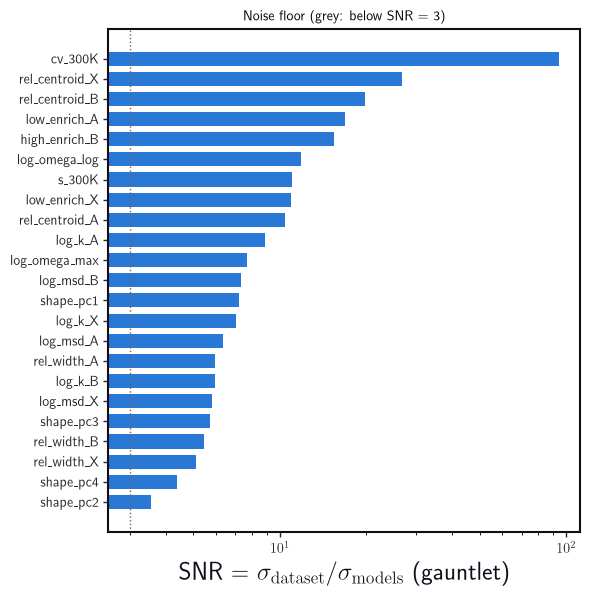

In [6]:
def noise_sigma(path: Path) -> pd.Series:
    b = pd.read_csv(path)
    b = b[b["error"].isna()] if "error" in b else b
    tb = phonon_targets(b)
    qb = np.load(path.with_name(path.stem + "_quantiles.npz"))
    qmap_b = dict(zip(qb["keys"], qb["quantiles_cm1"]))
    Qb = np.array([qmap_b[k] for k in b["key"]])
    sb = shape_pca.transform(Qb / Qb.mean(axis=1, keepdims=True))
    for k in range(n_shape):
        tb[f"shape_pc{k + 1}"] = sb[:, k]
    # model-to-model std per structure, then the median over structures
    return tb.groupby(b["structure"]).std().median()


noise = pd.DataFrame({name: noise_sigma(p) for name, p in NOISE_CSVS.items() if p.exists()})
snr = pd.DataFrame({name: T.std() / noise[name] for name in noise})
print(snr.round(1).sort_values(snr.columns[0]).to_string())

if DFPT_METRICS_CSV.exists():
    dfpt = pd.read_csv(DFPT_METRICS_CSV)
    print("\nMLIP vs DFPT (5 cubic cells x models): RMS error / dataset std")
    for col, tgt in [("cv_kB_err", "cv_300K"), ("s_kB_err", "s_300K")]:
        print(f"  {tgt}: {np.sqrt((dfpt[col] ** 2).mean()) / T[tgt].std():.2f}")

primary = snr.columns[0]
s = snr[primary].dropna().sort_values()
fig, ax = plt.subplots(figsize=(6, 0.22 * len(s) + 1))
ax.barh(s.index, s.values, color=[HIGHLIGHT if v >= 3 else CONTEXT for v in s.values], height=0.7)
ax.axvline(3, color="0.4", lw=1, ls=":")
ax.set_xscale("log")
ax.set_xlabel(r"SNR = $\sigma_\mathrm{dataset}/\sigma_\mathrm{models}$ " + f"({primary.split(' (')[0]})")
ax.set_title("Noise floor (grey: below SNR = 3)", fontsize=10)
fig.tight_layout()

## How much of each target is the anion alone?

η² = fraction of variance explained by anion family, and by the chemical clusters from cluster_compositions.py. A target that's
mostly anion only has a few attainable values, and a composition model will just learn the anion. The interesting design range is
the residual within an anion family.

In [7]:
def eta_squared(y: pd.Series, labels: pd.Series) -> float:
    ok = y.notna() & labels.notna()
    y, labels = y[ok], labels[ok]
    within = ((y - y.groupby(labels).transform("mean")) ** 2).sum()
    return float(1 - within / ((y - y.mean()) ** 2).sum())


eta = pd.DataFrame({
    "anion family": {c: eta_squared(T[c], df["anion_family"]) for c in T},
    "chem cluster": {c: eta_squared(T[c], df["chem_cluster"]) for c in T},
})
print(eta.round(2).sort_values("anion family", ascending=False).to_string())

                       anion family  chem cluster
log_omega_log                  0.87          0.93
s_300K                         0.87          0.94
log_msd_B                      0.84          0.86
log_msd_A                      0.84          0.91
log_k_X                        0.84          0.90
log_omega_max                  0.83          0.89
log_k_A                        0.83          0.93
cv_300K                        0.82          0.88
log_k_B                        0.81          0.86
log_msd_X                      0.78          0.89
high_enrich_B                  0.71          0.68
rel_centroid_X                 0.70          0.77
rel_centroid_B                 0.65          0.68
rel_width_B                    0.62          0.68
low_enrich_X                   0.62          0.69
rel_width_X                    0.37          0.59
low_enrich_A                   0.33          0.49
rel_centroid_A                 0.28          0.36
shape_pc2                      0.27          0.20


## Check 2: redundancy

The Spearman correlation between targets, clustered. Targets in a block with |ρ| > 0.85 measure the same thing, so model one of them.
The participation ratio of the target correlation spectrum estimates how many independent phonon directions this dataset has.

participation ratio: 4.6 effective dimensions out of 26 targets


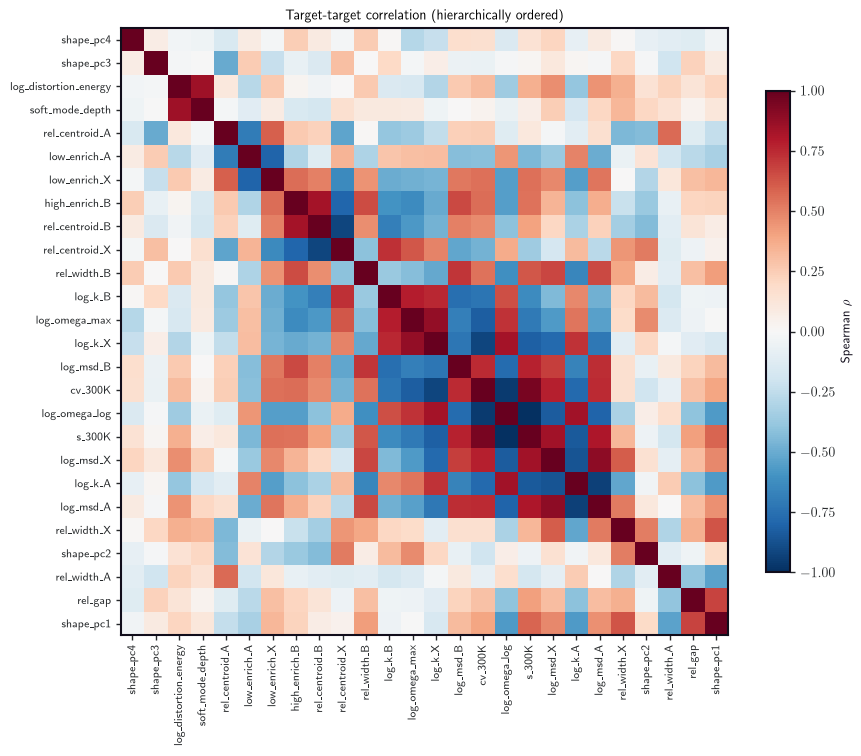

In [8]:
rho = T.corr(method="spearman")
dist = 1 - rho.abs().fillna(0).to_numpy()
np.fill_diagonal(dist, 0)
order = leaves_list(linkage(squareform(dist, checks=False), "average"))
rho_ord = rho.iloc[order, order]

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(rho_ord, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(rho_ord)), rho_ord.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(rho_ord)), rho_ord.index, fontsize=8)
fig.colorbar(im, ax=ax, shrink=0.7).set_label(r"Spearman $\rho$", fontsize=9)
ax.set_title("Target-target correlation (hierarchically ordered)", fontsize=10)
fig.tight_layout()

ev = np.clip(np.linalg.eigvalsh(T.rank().corr().fillna(0).to_numpy()), 0, None)
print(f"participation ratio: {ev.sum() ** 2 / (ev ** 2).sum():.1f} effective dimensions out of {len(T.columns)} targets")

## Check 3: learnability

Gradient-boosted trees (which handle the missing geometry/instability values natively) for every target and input tier:

- **R²(formula CV)**: 5-fold GroupKFold over formulas, so polymorphs of one formula never sit on both sides of a split.
  This measures interpolation within known chemistries.
- **R²(within family)**: the same CV predictions, but scored against each anion family's own mean, so only the within-family
  variance counts. For the absolute targets, 80–90% of the variance is which anion family a compound belongs to (see η² above),
  so the plain R² is mostly "the model knows the anion". This is the number that matters for designing inside a family.
- Instability targets (`log_distortion_energy`, `soft_mode_depth`) aren't scored with the **I** tier, which contains them.
- **R²(held-out anion)**: train on three anion families and predict the fourth, scored against the held-out family's own
  variance. This is harsh, but it's the inverse-design use case: proposing chemistries outside the training distribution.

**M** (site masses alone) is not a "trivial mass" baseline. Under formula CV, the masses identify the elements, so **M** scores high even on
the mass-free stiffnesses `log_k_*`. Read **M** as "element identity, no chemistry descriptors". The gap between **C** and **C+G** within a
family is what you'd pay a relaxation per candidate for.

In [9]:
def model():
    return HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, max_leaf_nodes=15,
                                         min_samples_leaf=10, l2_regularization=1.0, random_state=SEED)


def cv_r2(y: pd.Series, features: list[str], groups: pd.Series, n_splits: int = 5) -> tuple[float, float]:
    # (R2, within-anion-family R2) of grouped-CV predictions
    ok = y.notna().to_numpy()
    X, yv, g = X_all.loc[ok, features].to_numpy(), y[ok].to_numpy(), groups[ok].to_numpy()
    pred = np.empty_like(yv)
    for tr, te in GroupKFold(n_splits=n_splits).split(X, yv, g):
        pred[te] = model().fit(X[tr], yv[tr]).predict(X[te])
    family_mean = pd.Series(yv).groupby(df["anion_family"][ok].to_numpy()).transform("mean").to_numpy()
    within = 1 - ((yv - pred) ** 2).sum() / ((yv - family_mean) ** 2).sum()
    return r2_score(yv, pred), float(within)


def held_out_anion_r2(y: pd.Series, features: list[str], min_n: int = 40) -> dict:
    out = {}
    for fam in df["anion_family"].unique():
        te = (df["anion_family"] == fam) & y.notna()
        tr = (df["anion_family"] != fam) & y.notna()
        if fam == "other" or te.sum() < min_n:
            continue
        m = model().fit(X_all.loc[tr, features], y[tr])
        out[fam] = r2_score(y[te], m.predict(X_all.loc[te, features]))
    return out


learn = {}
for tgt in T.columns:
    row = {}
    for tier, feats in TIERS.items():
        r2, r2_within = ((np.nan, np.nan) if tier == "C+G+I" and tgt in INSTABILITY_TARGETS
                         else cv_r2(T[tgt], feats, df["formula"]))
        row[f"R2 {tier}"], row[f"R2w {tier}"] = r2, r2_within
    ho = held_out_anion_r2(T[tgt], TIERS["C+G"])
    row["R2 held-out anion (C+G, median)"] = np.median(list(ho.values())) if ho else np.nan
    row.update({f"held-out {k}": v for k, v in ho.items()})
    learn[tgt] = row
learn = pd.DataFrame(learn).T
print(learn.round(2).sort_values("R2w C+G", ascending=False).to_string())

                       R2 M  R2w M  R2 C  R2w C  R2 C+G  R2w C+G  R2 C+G+I  R2w C+G+I  R2 held-out anion (C+G, median)  held-out oxide  held-out fluoride  held-out bromide/iodide  held-out chloride
rel_centroid_B         0.97   0.92  0.98   0.95    0.98     0.96      0.98       0.96                             0.37            0.38               0.45                    -0.16               0.35
rel_centroid_X         0.98   0.93  0.99   0.95    0.99     0.96      0.99       0.96                             0.22            0.43               0.66                    -0.26               0.01
s_300K                 0.97   0.80  0.98   0.86    0.99     0.94      0.99       0.93                            -0.96           -1.02              -0.91                    -1.78               0.34
rel_centroid_A         0.90   0.87  0.93   0.91    0.95     0.93      0.95       0.93                             0.75            0.64               0.88                     0.52               0.86
log_omega_

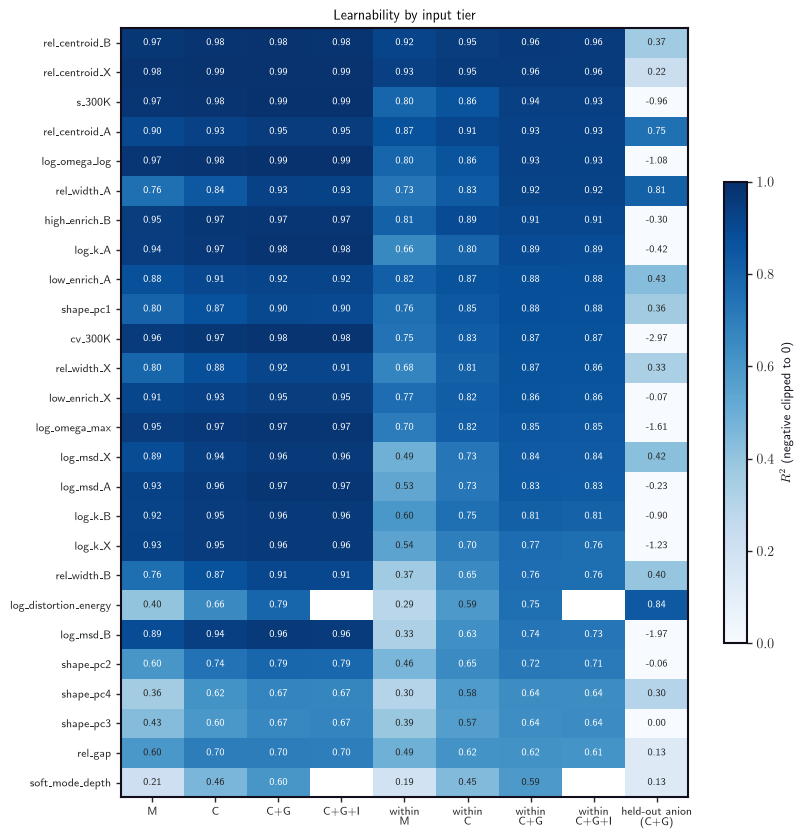

In [10]:
cols = [f"R2 {t}" for t in TIERS] + [f"R2w {t}" for t in TIERS] + ["R2 held-out anion (C+G, median)"]
L = learn[cols].sort_values("R2w C+G", ascending=False)
fig, ax = plt.subplots(figsize=(8.5, 0.28 * len(L) + 1.2))
im = ax.imshow(L.clip(lower=0), cmap="Blues", vmin=0, vmax=1, aspect="auto")
for (r, c), v in np.ndenumerate(L.to_numpy()):
    if np.isnan(v):
        continue
    ax.text(c, r, f"{v:.2f}", ha="center", va="center", fontsize=7, color="white" if v > 0.6 else "0.15")
ax.set_xticks(range(len(cols)), [c.replace("R2w ", "within\n").replace("R2 ", "").replace(" (C+G, median)", "\n(C+G)")
                                  for c in cols], fontsize=8)
ax.set_yticks(range(len(L)), L.index, fontsize=8)
fig.colorbar(im, ax=ax, shrink=0.6).set_label(r"$R^2$ (negative clipped to 0)", fontsize=9)
ax.set_title("Learnability by input tier", fontsize=10)
fig.tight_layout()

## Check 4: invertibility (degeneracy of target → chemistry)

For each target, take each polymorph's k nearest neighbours in that target alone and measure how far apart they are in the
standardized **C** descriptor space, relative to random pairs:

- ρ_inv ≈ 1: the target value says almost nothing about chemistry, so many routes reach the same value. That's good for
  "multiple synthetic routes", but the inverse map is broad.
- ρ_inv ≪ 1: the target pins the chemistry down, so the inverse is nearly unique.

Read this together with learnability. A target that's learnable but has ρ_inv near 1 means the forward model works from structure
in ways that composition-space distances don't capture, so there are several distinct chemical recipes for it.

In [11]:
Xc = X_all[C_FEATURES]
Xc = StandardScaler().fit_transform(Xc.fillna(Xc.median()))
rng = np.random.default_rng(SEED)
a, b = rng.integers(0, len(Xc), (2, 20000))
random_dist = np.median(np.linalg.norm(Xc[a] - Xc[b], axis=1))


def inverse_ratio(y: pd.Series, k: int = 10) -> float:
    ok = np.where(y.notna())[0]
    order = ok[np.argsort(y.iloc[ok].to_numpy())]
    d = []
    for pos in range(len(order)):  # neighbours in a 1D target are adjacent in sorted order
        nb = order[max(0, pos - k // 2): pos + k // 2 + 1]
        nb = nb[nb != order[pos]]
        d.append(np.median(np.linalg.norm(Xc[nb] - Xc[order[pos]], axis=1)))
    return float(np.median(d) / random_dist)


inv = pd.Series({t: inverse_ratio(T[t]) for t in T.columns}, name="rho_inv")
print(inv.sort_values().round(2).to_string())

log_k_A                  0.69
log_omega_log            0.69
s_300K                   0.69
cv_300K                  0.69
log_msd_A                0.72
log_omega_max            0.73
log_k_X                  0.74
log_k_B                  0.75
high_enrich_B            0.77
rel_centroid_B           0.77
log_msd_B                0.77
log_msd_X                0.77
rel_centroid_X           0.77
low_enrich_X             0.80
rel_width_B              0.82
rel_width_X              0.85
shape_pc1                0.88
log_distortion_energy    0.88
low_enrich_A             0.88
rel_centroid_A           0.89
rel_width_A              0.90
rel_gap                  0.90
shape_pc2                0.90
soft_mode_depth          0.92
shape_pc3                0.93
shape_pc4                0.93


## What predicts the learnable targets?

Permutation importance on a held-out 20% split (grouped by formula) for the **C+G** model, shown for the targets that pass the
noise and learnability checks. This shows which structure/composition descriptors carry the phonon information, i.e. the
structural side of the model.

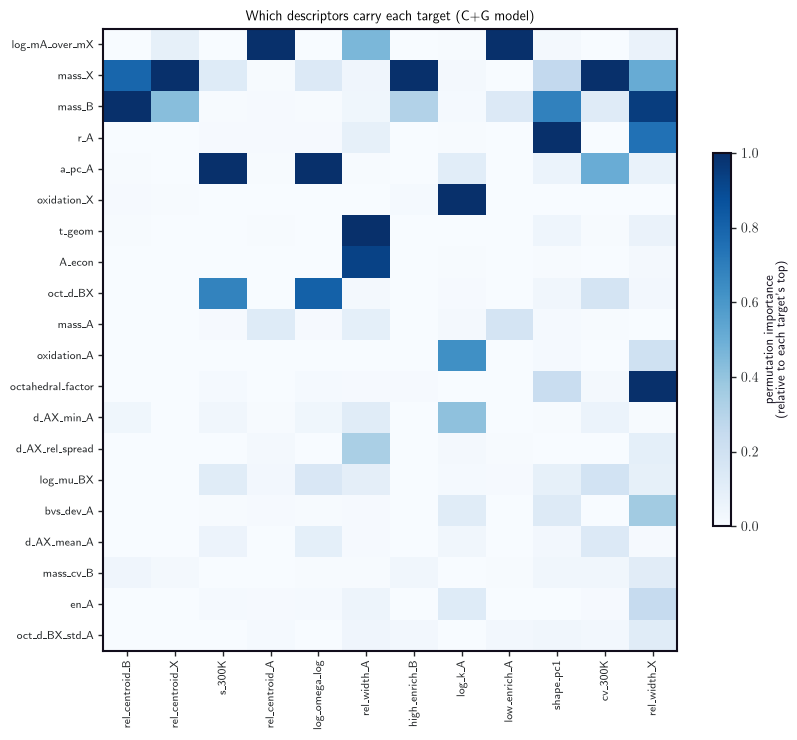

In [12]:
pass_mask = (learn["R2w C+G"] >= 0.5) & (snr[primary].reindex(T.columns).fillna(np.inf) >= 3)
show = list(learn[pass_mask].sort_values("R2w C+G", ascending=False).index[:12])
feats = TIERS["C+G"]
imp = {}
for tgt in show:
    y = T[tgt]
    ok = y.notna().to_numpy()
    tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
                  .split(X_all[ok], groups=df["formula"][ok]))
    Xo, yo = X_all.loc[ok, feats], y[ok]
    m = model().fit(Xo.iloc[tr], yo.iloc[tr])
    r = permutation_importance(m, Xo.iloc[te], yo.iloc[te], n_repeats=5, random_state=SEED)
    imp[tgt] = pd.Series(r.importances_mean, index=feats)
imp = pd.DataFrame(imp)
top_feats = imp.max(axis=1).sort_values(ascending=False).index[:20]
I_norm = (imp.loc[top_feats] / imp.max()).clip(lower=0)

fig, ax = plt.subplots(figsize=(0.45 * len(show) + 3, 0.3 * len(top_feats) + 1.5))
im = ax.imshow(I_norm, cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(show)), show, rotation=90, fontsize=8)
ax.set_yticks(range(len(top_feats)), top_feats, fontsize=8)
fig.colorbar(im, ax=ax, shrink=0.6).set_label("permutation importance\n(relative to each target's top)", fontsize=9)
ax.set_title("Which descriptors carry each target (C+G model)", fontsize=10)
fig.tight_layout()

## Scorecard and a shortlist

The shortlist is built greedily by within-family R²(C+G). It skips any target with SNR < 3 or within-family R²(C+G) < 0.5, and any
target that correlates at |ρ| > 0.85 with one already picked. Thresholds are in the cell. Instability and gap targets have no SNR, because the noise sets
can't compute them, and they pass that check by default. Check their MLIP-vs-DFT behaviour separately before relying on them.

In [13]:
SNR_MIN, R2_MIN, RHO_MAX = 3.0, 0.5, 0.85

card = pd.concat([
    T.std().rename("dataset_std"),
    snr.add_prefix("SNR "),
    eta["anion family"].rename("eta2_anion"),
    learn[[f"R2 {t}" for t in TIERS] + [f"R2w {t}" for t in TIERS] + ["R2 held-out anion (C+G, median)"]],
    inv,
], axis=1)
# what relaxed geometry adds within a family (the cost of one relaxation per candidate)
card["geometry_gain_within"] = card["R2w C+G"] - card["R2w C"]

picked = []
for tgt in card.sort_values("R2w C+G", ascending=False).index:
    snr_ok = not (card.loc[tgt, f"SNR {primary}"] < SNR_MIN)  # NaN (not computable) passes
    if not snr_ok or card.loc[tgt, "R2w C+G"] < R2_MIN:
        continue
    if any(abs(rho.loc[tgt, p]) > RHO_MAX for p in picked):
        continue
    picked.append(tgt)
card["shortlist"] = card.index.isin(picked)

card.sort_values(["shortlist", "R2w C+G"], ascending=False).to_csv(OUT_DIR / "descriptor_scorecard.csv")
print("shortlist:", picked)
card.loc[picked].round(2)

shortlist: ['rel_centroid_B', 's_300K', 'rel_centroid_A', 'rel_width_A', 'high_enrich_B', 'log_k_A', 'low_enrich_A', 'shape_pc1', 'rel_width_X', 'low_enrich_X', 'log_omega_max', 'log_k_B', 'rel_width_B', 'log_distortion_energy', 'log_msd_B', 'shape_pc2', 'shape_pc4', 'shape_pc3', 'rel_gap', 'soft_mode_depth']


,dataset_std,"SNR gauntlet (Pnma CsPbBr3, relaxed per model)","SNR benchmark (5 cubic cells, DFT geometry)",eta2_anion,R2 M,R2 C,R2 C+G,R2 C+G+I,R2w M,R2w C,R2w C+G,R2w C+G+I,"R2 held-out anion (C+G, median)",rho_inv,geometry_gain_within,shortlist
rel_centroid_B,0.43,19.80,9.30,0.65,0.97,0.98,0.98,0.98,0.92,0.95,0.96,0.96,0.37,0.77,0.01,True
s_300K,1.23,11.06,8.55,0.87,0.97,0.98,0.99,0.99,0.80,0.86,0.94,0.93,-0.96,0.69,0.08,True
rel_centroid_A,0.14,10.43,3.68,0.28,0.90,0.93,0.95,0.95,0.87,0.91,0.93,0.93,0.75,0.89,0.02,True
rel_width_A,0.05,5.96,3.20,0.09,0.76,0.84,0.93,0.93,0.73,0.83,0.92,0.92,0.81,0.90,0.09,True
high_enrich_B,1.44,15.49,14.28,0.71,0.95,0.97,0.97,0.97,0.81,0.89,0.91,0.91,-0.30,0.77,0.01,True
log_k_A,0.76,8.92,4.91,0.83,0.94,0.97,0.98,0.98,0.66,0.80,0.89,0.89,-0.42,0.69,0.09,True
low_enrich_A,1.15,16.88,2.56,0.33,0.88,0.91,0.92,0.92,0.82,0.87,0.88,0.88,0.43,0.88,0.01,True
shape_pc1,0.92,7.19,4.24,0.19,0.80,0.87,0.90,0.90,0.76,0.85,0.88,0.88,0.36,0.88,0.04,True
rel_width_X,0.12,5.09,5.73,0.37,0.80,0.88,0.92,0.91,0.68,0.81,0.87,0.86,0.33,0.85,0.05,True
low_enrich_X,0.36,10.93,4.68,0.62,0.91,0.93,0.95,0.95,0.77,0.82,0.86,0.86,-0.07,0.80,0.04,True


## Reading the scorecard

- **eta2_anion** close to 1: the target mostly says which anion family a compound is in. Within a family it has only a narrow
  range to design over, so judge it by **R2w**, not **R2**.
- A large **geometry_gain_within**: the target depends on the realized polymorph (tilt, distortion) more than on composition.
  Build a two-stage model (composition → tilt/ECoN/bvs_dev → phonon target) and check the first stage separately.
- A low **held-out anion** R² while formula CV is good: the model interpolates within anion families but doesn't transfer across them.
  Prefer scale-free targets (`rel_*`, `*_enrich_*`, `shape_pc*`) for cross-family design.
- **rho_inv** near 1 with high learnability: there are several distinct chemical routes to the same phonon value. That's what
  cluster_compositions.py's top-N check is looking for, now per target.

Next steps: rerun the noise floor once the DFPT tilted-cell runs exist (true error rather than model spread). Then fit the
shortlist jointly as a multi-output model, which is the forward surrogate for screening the enumerated compositions.

## Halide interpolation: does the model fill in Cl–Br–I mixtures?

The held-out-anion test above treats chlorides, bromides and iodides as unrelated families, and the absolute frequency targets
don't transfer across them. The mixed-halide sweep (`data/mixed_halides`: one SQS per composition, x = 1/6 … 5/6 along each
series between two MP end members of the same framework) supplies the points in between. Three tests, all with the **C+G**
inputs (X-site radius, mass and electronegativity are stoichiometric averages, plus the `x_frac_*` halide shares):

1. **MP → mixed**: train on the MP polymorphs only and predict every mixed composition. Scored against the mixed set's own mean
   (R²), and against each series' own mean (**R²(series)**: only the variation along x counts). The baseline is linear
   interpolation between the two end members' MLIP values (Vegard-like), for series where both end members are kept polymorphs.
   A model that beats it has learned something about bowing; one far below it hasn't learned the x-dependence.
2. **held-out pair**: train on MP plus the mixed series of the other two halide pairs, predict the third. Compared with the
   MP-only model on the same rows, this shows whether mixed data from other pairs helps.
3. **held-out pure family, ± mixed data**: the held-out-anion test for chloride and bromide/iodide, with and without all mixed
   halides added to the training set. The mixed series contain the held-out halide (and often the same frameworks), so this is
   not a test on unseen chemistry. It measures whether mixtures bridge the families the way end-member data alone doesn't.

Instability targets are left out: the SQS cells are P1, so they have no symmetric parent. `rel_gap` isn't in the mixed tables.
Each composition is one SQS realization, so part of the residual is disorder noise, which isn't measured yet.

In [14]:
mdesign = pd.read_csv(MIXED_DESIGN_CSV)
msel = pd.read_csv(MIXED_SELECTION_CSV)
msel["key"] = msel["run_name"] + "/" + msel["state"]
mcomp = pd.read_csv(MIXED_COMP_CSV).rename(columns={"name": "run_name"})
series = (pd.read_csv(MIXED_SERIES_CSV).rename(columns={"structures": "run_name"})
          [["run_name", "framework", "X1", "X2", "end_X1", "end_X2"]])
dm = (mdesign.merge(msel[["key", "dynamically_stable", "crystal_system"]], on="key", how="inner")
             .merge(mcomp, on="run_name", how="left").merge(series, on="run_name", how="inner"))
n0 = len(dm)
if "error" in dm:
    dm = dm[dm["error"].isna()]
dm = dm[dm["dynamically_stable"].astype(bool) & (dm["sublattice_unassigned"] == 0)
        & (dm["n_A"] > 0) & (dm["n_B"] > 0)].reset_index(drop=True)
dm["pair"] = dm["X1"] + "/" + dm["X2"]
dm["x2"] = [row[f"x_frac_{row['X2']}"] for _, row in dm.iterrows()]
dm["series"] = dm["framework"] + " " + dm["pair"]
print(f"{len(dm)}/{n0} mixed compositions kept, {dm['series'].nunique()} series")
print(dm["pair"].value_counts().to_string())

Tm = phonon_targets(dm)
mq = np.load(MIXED_DESIGN_CSV.with_name("design_descriptors_quantiles.npz"))
mqmap = dict(zip(mq["keys"], mq["quantiles_cm1"]))
Qm = np.array([mqmap[k] for k in dm["key"]])
sm = shape_pca.transform(Qm / Qm.mean(axis=1, keepdims=True))  # the MP shape basis
for k in range(n_shape):
    Tm[f"shape_pc{k + 1}"] = sm[:, k]
Xm = input_features(dm)
HALIDE_TARGETS = [t for t in T.columns if t in Tm.columns and t not in INSTABILITY_TARGETS]

# end members: MP run names; their kept polymorph's value (first, if several)
end_value = T.assign(run_name=df["run_name"]).groupby("run_name").first()
has_ends = dm["end_X1"].isin(end_value.index) & dm["end_X2"].isin(end_value.index)
print(f"\nboth end members kept for {has_ends.sum()}/{len(dm)} compositions")


993/1154 mixed compositions kept, 231 series
pair
Cl/Br    564
Br/I     218
Cl/I     211

both end members kept for 672/993 compositions


In [15]:
FEATS = TIERS["C+G"]


def r2_vs(y, pred, ref):
    # 1 - SSE / sum (y - ref)^2: ref = overall mean (R2) or per-series mean (R2 series)
    return float(1 - ((y - pred) ** 2).sum() / ((y - ref) ** 2).sum())


def fit_predict(tgt, X_tr, y_tr, X_te):
    ok = y_tr.notna()
    return model().fit(X_tr.loc[ok, FEATS], y_tr[ok]).predict(X_te[FEATS])


rows = {}
for tgt in HALIDE_TARGETS:
    y = Tm[tgt]
    ok = y.notna().to_numpy()
    series_mean = y.groupby(dm["series"]).transform("mean")
    row = {}
    # 1. MP only -> mixed, and the linear end-member baseline
    pred_mp = pd.Series(fit_predict(tgt, X_all, T[tgt], Xm), index=dm.index)
    row["R2 MP->mixed"] = r2_vs(y[ok], pred_mp[ok], y[ok].mean())
    row["R2series MP->mixed"] = r2_vs(y[ok], pred_mp[ok], series_mean[ok])
    e = ok & has_ends.to_numpy()
    lin = ((1 - dm["x2"]) * end_value[tgt].reindex(dm["end_X1"]).to_numpy()
           + dm["x2"] * end_value[tgt].reindex(dm["end_X2"]).to_numpy())
    e &= lin.notna().to_numpy()
    row["R2series model (end rows)"] = r2_vs(y[e], pred_mp[e], series_mean[e])
    row["R2series linear (end rows)"] = r2_vs(y[e], lin[e], series_mean[e])
    # 2. held-out halide pair, with the other pairs' mixtures in training
    with_mixed, mp_only = [], []
    for pair in dm["pair"].unique():
        te = (dm["pair"] == pair).to_numpy() & ok
        tr = ~te & ok
        pred = fit_predict(tgt, pd.concat([X_all, Xm[tr]]), pd.concat([T[tgt], y[tr]]), Xm[te])
        with_mixed.append(r2_vs(y[te], pred, series_mean[te]))
        mp_only.append(r2_vs(y[te], pred_mp[te], series_mean[te]))
    row["R2series held-out pair: MP only"] = np.median(mp_only)
    row["R2series held-out pair: + other pairs"] = np.median(with_mixed)
    # 3. held-out pure family, with and without the mixtures
    for fam in ["chloride", "bromide/iodide"]:
        te = (df["anion_family"] == fam) & T[tgt].notna()
        tr = ~te
        y_te = T.loc[te, tgt]
        base = fit_predict(tgt, X_all[tr], T.loc[tr, tgt], X_all[te])
        plus = fit_predict(tgt, pd.concat([X_all[tr], Xm]), pd.concat([T.loc[tr, tgt], y]), X_all[te])
        row[f"held-out {fam}"] = r2_vs(y_te, base, y_te.mean())
        row[f"held-out {fam} + mixed"] = r2_vs(y_te, plus, y_te.mean())
    rows[tgt] = row
halide = pd.DataFrame(rows).T
halide["shortlist"] = halide.index.isin(picked)
halide = halide.sort_values(["shortlist", "R2series MP->mixed"], ascending=False)
halide.to_csv(OUT_DIR / "descriptor_halide_interpolation.csv")
with pd.option_context("display.width", 250):
    print(halide.round(2).to_string())


                R2 MP->mixed  R2series MP->mixed  R2series model (end rows)  R2series linear (end rows)  R2series held-out pair: MP only  R2series held-out pair: + other pairs  held-out chloride  held-out chloride + mixed  held-out bromide/iodide  held-out bromide/iodide + mixed  shortlist
low_enrich_X            0.75                0.31                       0.35                        0.38                             0.25                                   0.40               0.49                       0.46                    -0.95                             0.53       True
low_enrich_A            0.72               -0.01                       0.11                        0.20                            -0.01                                   0.33               0.55                       0.71                    -0.32                             0.58       True
log_k_A                 0.81               -0.09                       0.01                       -1.74                        

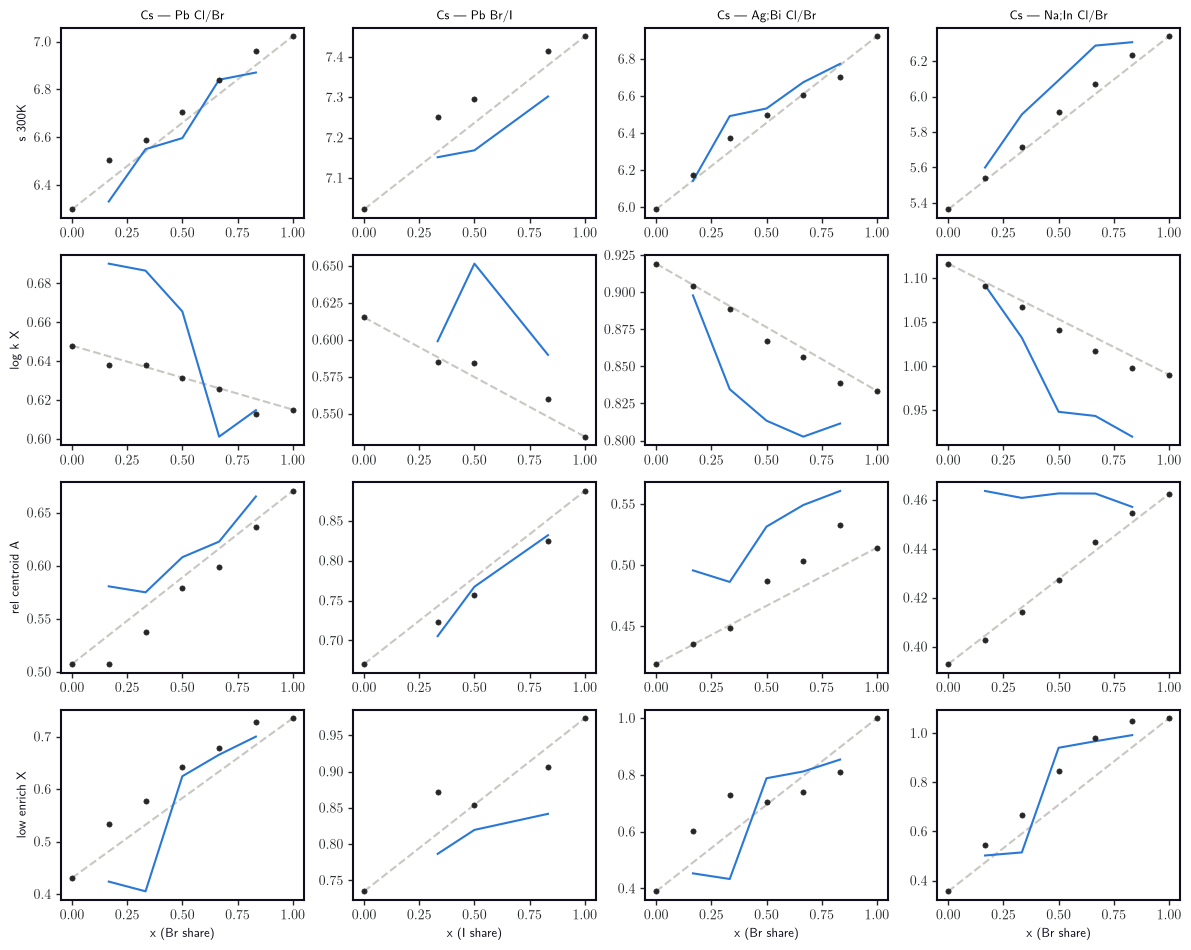

In [16]:
# a few series, target vs x: MLIP (dots, end members at x = 0, 1), MP-only model (line), linear end-member baseline (dashed)
show_t = [t for t in ["s_300K", "log_k_X", "rel_centroid_A", "low_enrich_X"] if t in HALIDE_TARGETS]
counts = dm[has_ends].groupby("series").size()
show_s = [s for s in ["Cs | Pb Cl/Br", "Cs | Pb Br/I", "Cs | Ag;Bi Cl/Br", "Cs | Na;In Cl/Br"] if s in counts.index]
show_s = (show_s + [s for s in counts.sort_values(ascending=False).index if s not in show_s])[:4]
fig, axes = plt.subplots(len(show_t), len(show_s), figsize=(3.0 * len(show_s), 2.4 * len(show_t)), squeeze=False)
for j, s in enumerate(show_s):
    rows_s = dm.index[dm["series"] == s]
    d_s = dm.loc[rows_s].sort_values("x2")
    for i, tgt in enumerate(show_t):
        ax = axes[i, j]
        e1, e2 = d_s["end_X1"].iloc[0], d_s["end_X2"].iloc[0]
        ends = [end_value.loc[e1, tgt], end_value.loc[e2, tgt]]
        pred = fit_predict(tgt, X_all, T[tgt], Xm.loc[d_s.index])
        ax.plot([0, 1], ends, ls="--", color=CONTEXT, lw=1.5)
        ax.plot(d_s["x2"], pred, color=HIGHLIGHT, lw=1.5)
        ax.scatter(np.r_[0, d_s["x2"], 1], np.r_[ends[0], Tm.loc[d_s.index, tgt], ends[1]], color="0.15", s=14, zorder=3)
        if i == 0:
            ax.set_title(s.replace("_", " "), fontsize=9)
        if j == 0:
            ax.set_ylabel(tgt.replace("_", " "), fontsize=9)
        if i == len(show_t) - 1:
            ax.set_xlabel(f"x ({d_s['X2'].iloc[0]} share)", fontsize=9)
fig.tight_layout()


**Reading it.** R²(series) is the strict number: it counts only how the target changes along a series, with each
framework's offset removed. The linear end-member baseline is what the MLIP data already says without any model. A large gap
from "MP only" to "+ other pairs" in test 2, or from the bare to the "+ mixed" columns in test 3, means mixed-halide data teaches
the model something that pure-halide data alone doesn't.

## Gaussian process vs trees for the halide interpolation

The trees above predict piecewise-constant steps along x, so even a perfect model of the framework offsets scores badly on
R²(series). A Gaussian process (ARD squared-exponential kernel plus white noise on the median-imputed, standardized **C+G**
inputs; `normalize_y`) is smooth in every input, including the stoichiometric X-site averages and the `x_frac_*` shares, so it can
interpolate between end members. Same tests, same rows, same scores as the tree table above, plus the MP grouped-CV within-family
R² for comparison with the scorecard.

The kernel hyperparameters are fitted (by marginal likelihood, on a random 1000-row subsample of that split's training set) for
every split, never on test rows. That takes ~3 h on 12 cores for all targets, so the fit is not repeated here: it is
`gp_vs_tree/gp_try.py` (inputs from this notebook via `gp_vs_tree/gp_setup.py`), and this section reads its `gp_all.csv` and
per-target held-out predictions. `gp_vs_tree/plot_gp_vs_tree.py` draws the full per-target comparison.

In [17]:
GP_DIR = PROJECT_ROOT / "gp_vs_tree"
gp = pd.read_csv(GP_DIR / "gp_all.csv", index_col=0).drop(columns="sec")
gp["R2series linear (end rows)"] = halide["R2series linear (end rows)"]
gp_pred = {t: pd.read_csv(GP_DIR / f"pred_{t}.csv").set_index("run_name") for t in gp.index}
GP_TESTS = {"MP R2w": "MP within-family (CV)", "R2series MP->mixed": "(1) MP only -> mixed, series",
            "R2series held-out pair": "(2) held-out pair, series", "held-out chloride +mixed": "(3) held-out chloride + mixed",
            "held-out bromide +mixed": "(3) held-out Br/I + mixed"}
print(pd.DataFrame({name: {"tree (median)": gp[f"{k} tree"].median(), "GP (median)": gp[f"{k} GP"].median(),
                           "GP better": f"{(gp[f'{k} GP'] > gp[f'{k} tree']).sum()}/{len(gp)}"}
                    for k, name in GP_TESTS.items()}).T.to_string())
cols = ["MP R2w tree", "MP R2w GP", "R2series held-out pair tree", "R2series held-out pair GP", "R2series linear (end rows)",
        "held-out chloride +mixed tree", "held-out chloride +mixed GP", "held-out bromide +mixed tree", "held-out bromide +mixed GP"]
gp[cols].sort_values("R2series held-out pair GP", ascending=False).round(2)

                              tree (median) GP (median) GP better
MP within-family (CV)              0.866927    0.860663     11/23
(1) MP only -> mixed, series      -1.223308   -1.524496     12/23
(2) held-out pair, series         -0.298698    0.018998     20/23
(3) held-out chloride + mixed      0.492927    0.801313     22/23
(3) held-out Br/I + mixed          0.681137     0.78815     17/23


,MP R2w tree,MP R2w GP,R2series held-out pair tree,R2series held-out pair GP,R2series linear (end rows),held-out chloride +mixed tree,held-out chloride +mixed GP,held-out bromide +mixed tree,held-out bromide +mixed GP
s_300K,0.94,0.93,0.62,0.95,0.93,0.49,0.94,0.92,0.89
log_omega_log,0.93,0.92,0.56,0.95,0.93,0.32,0.95,0.91,0.88
rel_centroid_X,0.96,0.97,0.32,0.80,0.81,0.42,0.95,0.85,0.89
log_k_A,0.89,0.92,0.42,0.79,-1.74,0.81,0.91,0.77,0.86
rel_centroid_A,0.93,0.95,0.14,0.68,0.19,0.94,0.98,0.90,0.94
log_k_B,0.81,0.79,0.20,0.68,-0.78,-1.05,0.59,0.76,0.66
rel_centroid_B,0.96,0.96,-0.88,0.64,-1.09,0.30,0.96,0.90,0.91
low_enrich_A,0.88,0.87,0.33,0.61,0.20,0.71,0.90,0.58,0.48
low_enrich_X,0.86,0.86,0.40,0.52,0.38,0.46,0.67,0.53,0.62
cv_300K,0.87,0.84,-0.59,0.44,0.90,-1.61,0.49,0.57,0.80


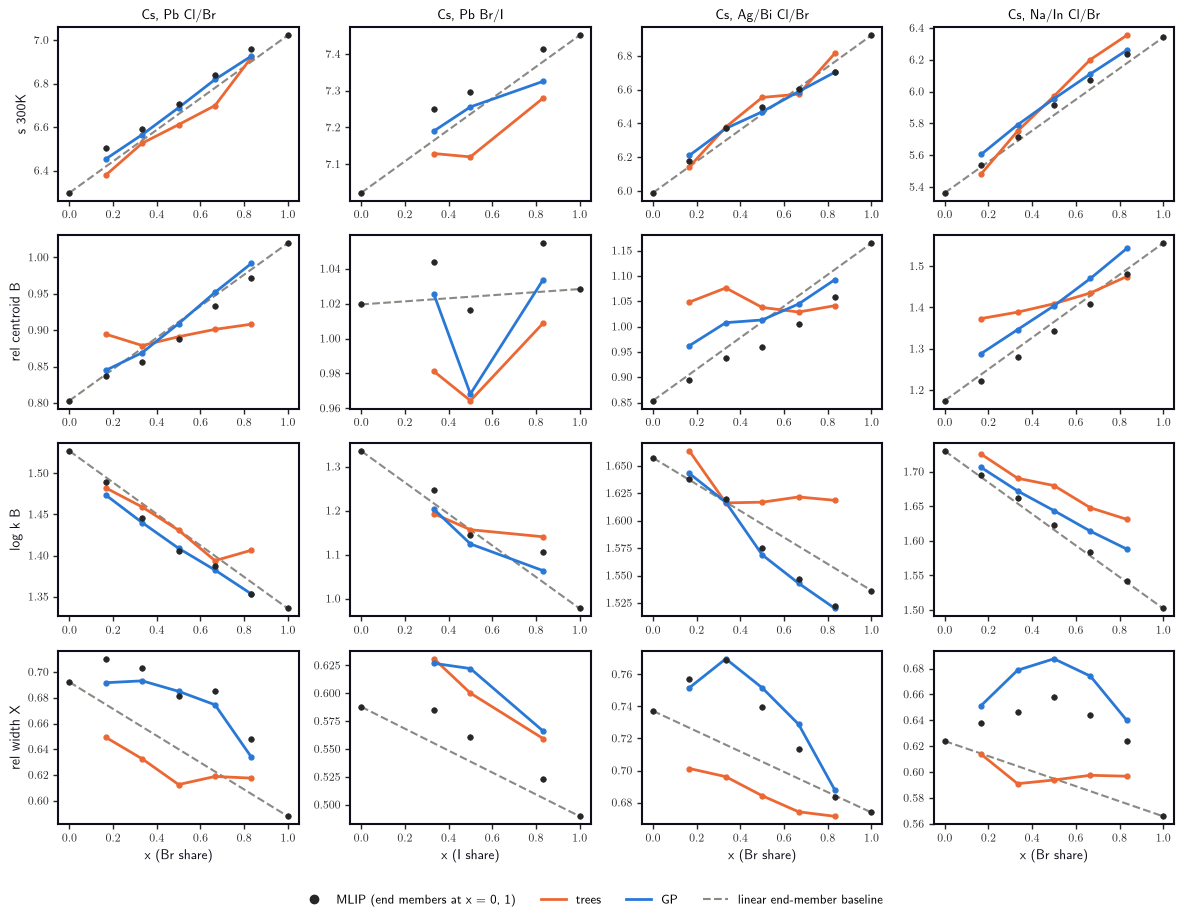

In [18]:
# held-out-pair predictions along a few series: each panel's halide pair was not in training (MP + the other two pairs' mixtures)
GP_C, TREE_C, BASE_C = "#2a78d6", "#eb6834", "#8a8984"
show_t = ["s_300K", "rel_centroid_B", "log_k_B", "rel_width_X"]
show_s = [s for s in ["Cs | Pb Cl/Br", "Cs | Pb Br/I", "Cs | Ag;Bi Cl/Br", "Cs | Na;In Cl/Br"] if s in counts.index]
show_s = (show_s + [s for s in counts.sort_values(ascending=False).index if s not in show_s])[:4]
fig, axes = plt.subplots(len(show_t), len(show_s), figsize=(3.0 * len(show_s), 2.3 * len(show_t)), squeeze=False)
for j, s in enumerate(show_s):
    d_s = dm[dm["series"] == s].sort_values("x2")
    e1, e2 = d_s["end_X1"].iloc[0], d_s["end_X2"].iloc[0]
    for i, tgt in enumerate(show_t):
        ax = axes[i, j]
        ends = [end_value.loc[e1, tgt], end_value.loc[e2, tgt]]
        p = gp_pred[tgt].loc[d_s["run_name"]]
        ax.plot([0, 1], ends, ls="--", color=BASE_C, lw=1.5)
        ax.plot(d_s["x2"], p["pair tree"], color=TREE_C, lw=2, marker="o", ms=3.5)
        ax.plot(d_s["x2"], p["pair GP"], color=GP_C, lw=2, marker="o", ms=3.5)
        ax.scatter(np.r_[0, d_s["x2"], 1], np.r_[ends[0], Tm.loc[d_s.index, tgt], ends[1]], color="0.15", s=16, zorder=4)
        ax.tick_params(labelsize=8)
        if i == 0:
            ax.set_title(s.replace(" | ", ", ").replace(";", "/"), fontsize=9.5)
        if j == 0:
            ax.set_ylabel(tgt.replace("_", " "), fontsize=10)
        if i == len(show_t) - 1:
            ax.set_xlabel(f"x ({d_s['X2'].iloc[0]} share)", fontsize=9.5)
fig.legend(handles=[plt.Line2D([], [], color="0.15", marker="o", ls="", label="MLIP (end members at x = 0, 1)"),
                    plt.Line2D([], [], color=TREE_C, lw=2, label="trees"),
                    plt.Line2D([], [], color=GP_C, lw=2, label="GP"),
                    plt.Line2D([], [], color=BASE_C, lw=1.5, ls="--", label="linear end-member baseline")],
           loc="lower center", ncol=4, fontsize=9)
fig.tight_layout(rect=(0, 0.04, 1, 1))

**Reading it.** On the MP scorecard the two models are equivalent. Trained on MP alone, neither captures the x-dependence:
pure end members don't constrain what happens between them. With the other pairs' mixtures in training, the GP's held-out-pair
R²(series) matches the linear end-member baseline for the frequency-scale targets (s_300K, log_omega_log) and exceeds it where the
mixtures bow (log_k_A, log_k_B, rel_centroid_A/B), while the trees plateau between their split points. Mixed data also bridges the
held-out pure families better through the GP (held-out chloride: 22 of 23 targets improve). The width, MSD and shape targets stay
below zero for every model, the linear baseline included; the next section checks whether that is the disorder noise of a single
SQS per composition.

## Disorder noise: is a single SQS enough?

Each production composition is one SQS realization, so its descriptors carry a disorder error: another equally good SQS of the
same composition gives different phonons. The noise check (`data/mixed_halides_noise_check_mp`, from
`scripts/dataset/select_noise_check_series.py`) repeats 23 production series (all five x, both end members stable, stratified by
halide pair and single / double perovskite; 115 compositions) with five SQS seeds each. Seed 0 is the production structure itself.
`scripts/analysis/sqs_ensemble_average.py` reduces the realizations to manifest-weighted ensemble averages (SQS cells that came out
symmetry-equivalent are pooled with their summed weight).

From that, per target:
- **seed_std**: the realization-to-realization spread, pooled over compositions (unbiased, from the seed counts the weights
  stand for). Only dynamically stable realizations count, as in production.
- **SNR_series**: the along-series spread of the ensemble means over the seed spread. Below ~1, a single SQS can't resolve the
  x-dependence at all.
- **ceiling**: the best R²(series) any model can reach against single-SQS production values on these rows,
  1 − seed_var / within-series variance of the production values. A model at its ceiling is limited by the data, not by itself.
- the linear baseline, trees and GP (held-out-pair predictions from the previous section) re-scored against the **ensemble
  mean** instead of the single SQS. If their R²(series) rises toward 1, the single-SQS noise was what held them back.
- **sqs0_repro**: |nc-sqs0 − production| over seed_std. ≈ 0 means the noise-check runs reproduce production (same structure,
  same pipeline).

In [19]:
from scripts.analysis.sqs_ensemble_average import realizations

NOISE_DIR = PROJECT_ROOT / "data" / "mixed_halides_noise_check_mp"
have_noise = (NOISE_DIR / "analysis" / "design_descriptors.csv").exists()
if not have_noise:
    print(f"no noise-check descriptors in {NOISE_DIR / 'analysis'} yet: run the MLIP sweep and the steps in "
          "scripts/analysis/sqs_ensemble_average.py's docstring; this section is skipped")
else:
    dn = realizations(NOISE_DIR)
    n_runs = len(dn)
    dn = dn[dn["dynamically_stable"].astype(bool) & (dn["sublattice_unassigned"] == 0)].reset_index(drop=True)
    n_sqs = int(pd.read_csv(NOISE_DIR / "manifest.csv")["seed"].max()) + 1
    dn["count"] = (dn["weight"] * n_sqs).round()  # seeds each (pooled) realization stands for
    Tn = phonon_targets(dn)
    nq = np.load(NOISE_DIR / "analysis" / "design_descriptors_quantiles.npz")
    nqmap = dict(zip(nq["keys"], nq["quantiles_cm1"]))
    Qn = np.array([nqmap[k] for k in dn["key"]])
    sn = shape_pca.transform(Qn / Qn.mean(axis=1, keepdims=True))
    for k in range(n_shape):
        Tn[f"shape_pc{k + 1}"] = sn[:, k]
    Tn = Tn[[t for t in HALIDE_TARGETS if t in Tn]]
    print(f"{len(dn)}/{n_runs} realizations stable, {dn['manifest_formula'].nunique()} compositions")

    def seed_stats(v: pd.Series) -> pd.DataFrame:
        # per composition: count-weighted mean and unbiased variance over seeds
        g = pd.DataFrame({"v": v, "c": dn["count"], "f": dn["manifest_formula"]}).dropna()
        n = g.groupby("f")["c"].sum()
        mean = (g["v"] * g["c"]).groupby(g["f"]).sum() / n
        ss = (g["c"] * (g["v"] - g["f"].map(mean)) ** 2).groupby(g["f"]).sum()
        return pd.DataFrame({"mean": mean, "var": (ss / (n - 1)).where(n > 1), "n": n})

    prod = dm[dm["formula"].isin(dn["manifest_formula"])]
    prod = prod[prod.groupby("series")["formula"].transform("size") > 1]
    sqs0 = dn[dn["run_name"].str.startswith("nc-sqs0")].set_index("manifest_formula")
    rows = {}
    for tgt in Tn.columns:
        st = seed_stats(Tn[tgt])
        noise_var = st["var"].mean()
        y = Tm.loc[prod.index, tgt]
        ens = pd.Series(st["mean"].reindex(prod["formula"]).to_numpy(), index=prod.index)
        ok = y.notna() & ens.notna()
        ser = prod.loc[ok, "series"]
        y, ens = y[ok], ens[ok]
        y_dev, ens_dev = y - y.groupby(ser).transform("mean"), ens - ens.groupby(ser).transform("mean")
        lin_t = ((1 - prod["x2"]) * end_value[tgt].reindex(prod["end_X1"]).to_numpy()
                 + prod["x2"] * end_value[tgt].reindex(prod["end_X2"]).to_numpy()).loc[ok.index[ok]]
        preds = {"linear": lin_t, "tree": gp_pred[tgt]["pair tree"].reindex(prod.loc[ok, "run_name"]).to_numpy(),
                 "GP": gp_pred[tgt]["pair GP"].reindex(prod.loc[ok, "run_name"]).to_numpy()}
        row = {"seed_std": np.sqrt(noise_var), "SNR_series": float(np.sqrt((ens_dev ** 2).mean() / noise_var)),
               "ceiling": 1 - noise_var / (y_dev ** 2).mean()}
        for name, p in preds.items():
            p = pd.Series(np.asarray(p, float), index=y.index)
            row[f"{name} vs single"] = r2_vs(y, p, y.groupby(ser).transform("mean"))
            row[f"{name} vs ensemble"] = r2_vs(ens, p, ens.groupby(ser).transform("mean"))
        prod_val = pd.Series(y.to_numpy(), index=prod.loc[ok, "formula"])
        t0 = pd.Series(Tn.loc[dn.index[dn["run_name"].str.startswith("nc-sqs0")], tgt].to_numpy(), index=sqs0.index)
        row["sqs0_repro"] = float((t0 - prod_val.reindex(t0.index)).abs().median() / np.sqrt(noise_var))
        rows[tgt] = row
    noise_tab = pd.DataFrame(rows).T
    noise_tab["shortlist"] = noise_tab.index.isin(picked)
    noise_tab = noise_tab.sort_values("SNR_series", ascending=False)
    noise_tab.to_csv(OUT_DIR / "descriptor_sqs_noise.csv")
    with pd.option_context("display.width", 250):
        print(noise_tab.round(2).to_string())

no noise-check descriptors in /home/rotskofflab6/Desktop/research/perovskite_phonon/data/mixed_halides_noise_check_mp/analysis yet: run the MLIP sweep and the steps in scripts/analysis/sqs_ensemble_average.py's docstring; this section is skipped


In [20]:
# per target: the noise ceiling on R2(series), and each model scored against the single SQS (open) and the ensemble mean (filled)
if have_noise:
    order = noise_tab.sort_values("SNR_series").index
    yy = np.arange(len(order))
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(10, 0.3 * len(order) + 1.8), sharey=True,
                                  gridspec_kw={"width_ratios": [2.2, 1]})
    floor = -2.0
    clip = lambda v: np.clip(np.asarray(v, float), floor, None)
    ax.scatter(clip(noise_tab.loc[order, "ceiling"]), yy, marker="|", s=120, color="0.15", lw=2, zorder=4)
    for name, c, dy in [("linear", BASE_C, 0.22), ("tree", TREE_C, 0), ("GP", GP_C, -0.22)]:
        ax.scatter(clip(noise_tab.loc[order, f"{name} vs single"]), yy + dy, facecolors="none", edgecolors=c, s=26, lw=1.3)
        ax.scatter(clip(noise_tab.loc[order, f"{name} vs ensemble"]), yy + dy, color=c, s=26, zorder=3)
    ax.axvline(0, color="0.5", lw=0.8, ls=":")
    ax.set_xlim(floor - 0.1, 1.05)
    ax.set_yticks(yy, [t.replace("_", " ") for t in order], fontsize=9)
    ax.set_xlabel(r"$R^2$(series), held-out pair; below $-2$ drawn at $-2$", fontsize=10)
    fig.legend(handles=[plt.Line2D([], [], color="0.15", marker="|", ls="", ms=10, mew=2, label="noise ceiling (single SQS)"),
                       plt.Line2D([], [], color=GP_C, marker="o", ls="", label="GP"),
                       plt.Line2D([], [], color=TREE_C, marker="o", ls="", label="trees"),
                       plt.Line2D([], [], color=BASE_C, marker="o", ls="", label="linear baseline"),
                       plt.Line2D([], [], color="0.4", marker="o", ls="", mfc="none", label="vs single SQS"),
                       plt.Line2D([], [], color="0.4", marker="o", ls="", label="vs ensemble mean")],
               fontsize=8.5, loc="lower center", ncol=6)
    ax2.barh(yy, noise_tab.loc[order, "SNR_series"], color=GP_C, height=0.6)
    ax2.axvline(1, color="0.5", lw=0.8, ls=":")
    ax2.set_xscale("log")
    ax2.xaxis.set_minor_formatter(plt.NullFormatter())
    ax2.set_xlabel("along-series spread / seed spread", fontsize=10)
    fig.tight_layout(rect=(0, 0.05, 1, 1))

**Reading it.** Targets with SNR_series near or below 1 and a low ceiling are disorder-limited at one SQS per composition:
no model can beat the ceiling against production values, and the remedy is an ensemble average (the noise-check directory already
holds one for these series), not a better regressor. Where the models score well against the ensemble mean but badly against the
single SQS, the earlier negative R²(series) was noise, not a modelling failure. Where they stay low against the ensemble mean too,
the x-dependence is real and still unlearned.